# UTS Graf Sains Data
Fawazul 'Ammar
24031554136

In [19]:
from getpass import getpass
PASSWORD = getpass("Password Neo4j: ")

Password Neo4j:  ········


In [22]:
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", PASSWORD)

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("TERHUBUNG dari notebook")

TERHUBUNG dari notebook


In [6]:
with driver.session() as s:
    r = s.run("RETURN gds.version() AS v").single()
    print("GDS versi:", r["v"])

GDS versi: 2026.09.0


In [ ]:
!curl.exe -L -o ecommerce-dataset.zip https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset

In [10]:
import zipfile, os

os.makedirs("data", exist_ok=True)
with zipfile.ZipFile("ecommerce-dataset.zip") as z:
    z.extractall("data")

print(os.listdir("data"))

['category_tree.csv', 'events.csv', 'item_properties_part1.csv', 'item_properties_part2.csv']


In [11]:
import os
import pandas as pd

df = pd.read_csv("data/events.csv")
print("Ukuran file:", round(os.path.getsize("data/events.csv") / 1e6, 1), "MB")
print("Shape      :", df.shape)
print(df.head())
print()
print("Mulai  :", pd.to_datetime(df.timestamp.min(), unit="ms"))
print("Selesai:", pd.to_datetime(df.timestamp.max(), unit="ms"))
print()
print(df.event.value_counts())
print()
print("Jumlah visitor unik:", df.visitorid.nunique())
print("Jumlah item unik   :", df.itemid.nunique())

Ukuran file: 94.2 MB
Shape      : (2756101, 5)
       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN

Mulai  : 2015-05-03 03:00:04.384000
Selesai: 2015-09-18 02:59:47.788000

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

Jumlah visitor unik: 1407580
Jumlah item unik   : 235061


## 2.1 No. 1-2: Periode dan Filter Waktu
- P1 (training): 17 Mei 2015 - 7 Juli 2015
- P2 (testing): 8 Juli 2015 - 5 Agustus 2015
- P2 berada setelah P1 (tidak tumpang tindih) agar tidak ada kebocoran data.
  P1 dipakai membangun graf, P2 dipakai sebagai kunci jawaban evaluasi.
- Filter diterapkan pada kolom timestamp (unix epoch, milidetik), hasilnya
  disimpan ke data/events_p1.csv dan data/events_p2.csv.
- P1 = 1.067.147 baris, P2 = 650.030 baris. Visitor yang ada di kedua periode: 19.536.

In [13]:
P1_START, P1_END = "2015-05-17", "2015-07-07"
P2_START, P2_END = "2015-07-08", "2015-08-05"

def to_ms(tgl, akhir_hari=False):
    t = pd.Timestamp(tgl)
    if akhir_hari:
        t = t + pd.Timedelta(days=1) - pd.Timedelta(milliseconds=1)
    return int(t.timestamp() * 1000)

p1 = df[(df.timestamp >= to_ms(P1_START)) & (df.timestamp <= to_ms(P1_END, True))]
p2 = df[(df.timestamp >= to_ms(P2_START)) & (df.timestamp <= to_ms(P2_END, True))]

print("P1 baris:", len(p1), "| visitor:", p1.visitorid.nunique(), "| item:", p1.itemid.nunique())
print(p1.event.value_counts().to_dict())
print()
print("P2 baris:", len(p2), "| visitor:", p2.visitorid.nunique(), "| item:", p2.itemid.nunique())
print(p2.event.value_counts().to_dict())
print()
print("Visitor yang ada di P1 DAN P2:", len(set(p1.visitorid) & set(p2.visitorid)))

P1 baris: 1067147 | visitor: 542513 | item: 155260
{'view': 1032502, 'addtocart': 26036, 'transaction': 8609}

P2 baris: 650030 | visitor: 357561 | item: 121074
{'view': 628207, 'addtocart': 16383, 'transaction': 5440}

Visitor yang ada di P1 DAN P2: 19536


In [14]:
p1.to_csv("data/events_p1.csv", index=False)
p2.to_csv("data/events_p2.csv", index=False)

for f in ["data/events_p1.csv", "data/events_p2.csv"]:
    print(f, "->", round(os.path.getsize(f) / 1e6, 1), "MB")

data/events_p1.csv -> 37.6 MB
data/events_p2.csv -> 22.9 MB


In [1]:
import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", PASSWORD)   
CSV_PATH = "data/events_p1.csv"
BATCH_SIZE = 10000

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

QUERIES = {
    "view": """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    """,
    "addtocart": """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    """,
    "transaction": """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    """,
}

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_unik IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_unik IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, query, records):
    tx.run(query, batch=records)

total_rows = sum(1 for _ in open(CSV_PATH)) - 1    
total_chunks = (total_rows // BATCH_SIZE) + 1
print("Total baris:", total_rows)

with driver.session() as session:
    create_constraints(session)
    chunks = pd.read_csv(CSV_PATH, chunksize=BATCH_SIZE)

    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor"):
        chunk["transactionid"] = chunk["transactionid"].fillna(0).astype(int)
        for jenis, query in QUERIES.items():
            bagian = chunk[chunk["event"] == jenis]
            if len(bagian) > 0:
                session.execute_write(import_batch, query, bagian.to_dict(orient="records"))

driver.close()
print("Proses impor selesai.")

Total baris: 1067147


Mengimpor: 100%|██████████| 107/107 [02:58<00:00,  1.67s/it]

Proses impor selesai.


In [24]:
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", PASSWORD) 

driver = GraphDatabase.driver(URI, auth=AUTH)

q_simpul = "MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah ORDER BY jumlah DESC"
q_relasi = "MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(*) AS jumlah ORDER BY jumlah DESC"

with driver.session() as s:
    print("=== SIMPUL ===")
    for r in s.run(q_simpul):
        print(r["jenis_simpul"], ":", r["jumlah"])

    print()
    print("=== RELASI ===")
    for r in s.run(q_relasi):
        print(r["jenis_relasi"], ":", r["jumlah"])

=== SIMPUL ===
Visitor : 542513
Item : 155260

=== RELASI ===
VIEWED : 1032502
ADDED_TO_CART : 26036
BOUGHT : 8609


## 2.1 No. 3: Komposisi Subgraph
Graf dibangun dari data P1 dengan dua jenis simpul dan tiga jenis relasi.

| Simpul | Jumlah |
|---|---|
| Visitor | 542.513 |
| Item | 155.260 |

| Relasi | Jumlah |
|---|---|
| VIEWED | 1.032.502 |
| ADDED_TO_CART | 26.036 |
| BOUGHT | 8.609 |

Total relasi 1.067.147, sama dengan jumlah baris P1.

**Cypher yang dipakai:**
```cypher
MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah
MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(*) AS jumlah
```
- `MATCH (n)` mencari semua simpul. `labels(n)[0]` mengambil labelnya.
- `MATCH ()-[r]->()` mencari semua relasi berarah. `type(r)` mengambil jenisnya.
- `count(*)` menghitung jumlah per kelompok. Cypher mengelompokkan otomatis
  berdasarkan kolom lain di RETURN, jadi tidak perlu GROUP BY.

In [25]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

p1 = pd.read_csv("data/events_p1.csv")

BOBOT = {"view": 1, "addtocart": 3, "transaction": 5}
p1["skor"] = p1["event"].map(BOBOT)

user_cat = p1["visitorid"].astype("category")
item_cat = p1["itemid"].astype("category")
n_user = len(user_cat.cat.categories)
n_item = len(item_cat.cat.categories)

M_user = csr_matrix(
    (p1["skor"].values, (user_cat.cat.codes.values, item_cat.cat.codes.values)),
    shape=(n_user, n_item),
)
M_item = M_user.T.tocsr()

def ringkas(nama, M, sisi):
    total = M.shape[0] * M.shape[1]
    print(f"=== VSM {nama} ===")
    print("Shape            :", M.shape)
    print("Sel terisi (nnz) :", M.nnz)
    print("Total sel        :", f"{total:,}")
    print("Sparsity         :", f"{100 * (1 - M.nnz / total):.4f} %")
    per_baris = np.diff(M.indptr)          # jumlah sel terisi tiap baris
    print(f"Rata-rata {sisi} per baris:", round(per_baris.mean(), 2))
    print("Maksimum per baris:", per_baris.max())
    print("Baris yg isinya cuma 1:", f"{(per_baris == 1).mean() * 100:.1f} %")
    print("Memori sparse    :", round((M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6, 1), "MB")
    print("Kalau dense      :", round(total * 8 / 1e9, 1), "GB")
    print()

ringkas("USER (baris = visitor, kolom = item)", M_user, "item")
ringkas("ITEM (baris = item, kolom = visitor)", M_item, "visitor")

=== VSM USER (baris = visitor, kolom = item) ===
Shape            : (542513, 155260)
Sel terisi (nnz) : 824482
Total sel        : 84,230,568,380
Sparsity         : 99.9990 %
Rata-rata item per baris: 1.52
Maksimum per baris: 1231
Baris yg isinya cuma 1: 79.8 %
Memori sparse    : 12.1 MB
Kalau dense      : 673.8 GB

=== VSM ITEM (baris = item, kolom = visitor) ===
Shape            : (155260, 542513)
Sel terisi (nnz) : 824482
Total sel        : 84,230,568,380
Sparsity         : 99.9990 %
Rata-rata visitor per baris: 5.31
Maksimum per baris: 1080
Baris yg isinya cuma 1: 43.3 %
Memori sparse    : 10.5 MB
Kalau dense      : 673.8 GB



Matplotlib is building the font cache; this may take a moment.


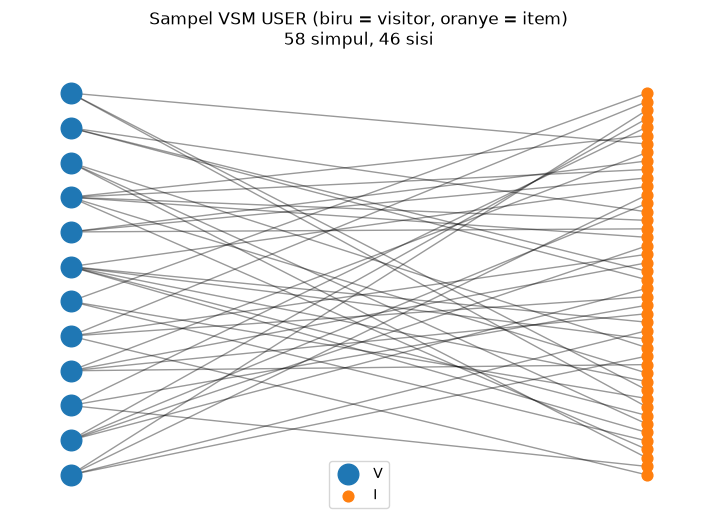

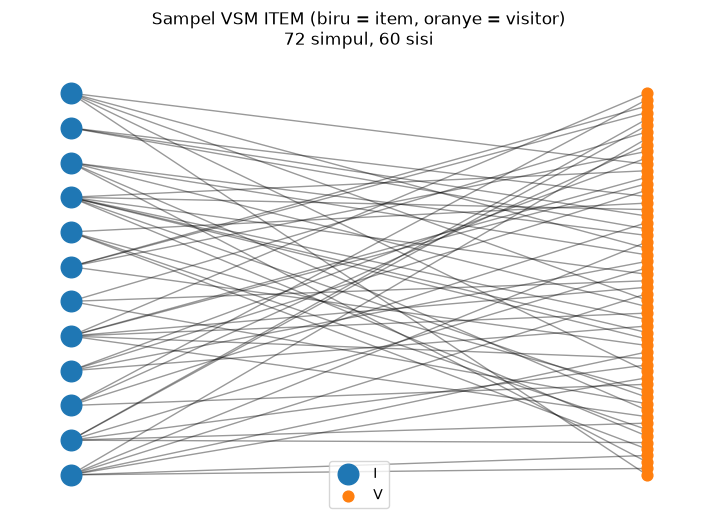

Perkiraan pasangan proyeksi User-User: 15,829,006
Perkiraan pasangan proyeksi Item-Item: 8,806,648
Jumlah simpul User-User: 542,513 | Item-Item: 155,260


In [22]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

def gambar(M, judul, label_baris, label_kolom, n=12, seed=42):
    deg = np.diff(M.indptr)
    kandidat = np.where((deg >= 3) & (deg <= 8))[0]
    rng = np.random.default_rng(seed)               # seed tetap = hasil bisa direproduksi
    pilih = rng.choice(kandidat, size=n, replace=False)

    G = nx.Graph()
    baris_nodes = [f"{label_baris}{r}" for r in pilih]
    for r in pilih:
        for c in M.indices[M.indptr[r]:M.indptr[r + 1]]:
            G.add_edge(f"{label_baris}{r}", f"{label_kolom}{c}")
    kolom_nodes = [x for x in G.nodes if x not in set(baris_nodes)]

    pos = nx.bipartite_layout(G, baris_nodes)
    plt.figure(figsize=(9, 6))
    nx.draw_networkx_nodes(G, pos, nodelist=baris_nodes, node_color="tab:blue", node_size=220, label=label_baris)
    nx.draw_networkx_nodes(G, pos, nodelist=kolom_nodes, node_color="tab:orange", node_size=60, label=label_kolom)
    nx.draw_networkx_edges(G, pos, alpha=0.4)
    plt.title(f"{judul}\n{G.number_of_nodes()} simpul, {G.number_of_edges()} sisi")
    plt.legend(scatterpoints=1)
    plt.axis("off")
    plt.show()

gambar(M_user, "Sampel VSM USER (biru = visitor, oranye = item)", "V", "I")
gambar(M_item, "Sampel VSM ITEM (biru = item, oranye = visitor)", "I", "V")

deg_user = np.diff(M_user.indptr).astype(np.int64)   # item per visitor
deg_item = np.diff(M_item.indptr).astype(np.int64)   # visitor per item
pasangan_user_user = int((deg_item * (deg_item - 1) // 2).sum())
pasangan_item_item = int((deg_user * (deg_user - 1) // 2).sum())

print("Perkiraan pasangan proyeksi User-User:", f"{pasangan_user_user:,}")
print("Perkiraan pasangan proyeksi Item-Item:", f"{pasangan_item_item:,}")
print("Jumlah simpul User-User:", f"{M_user.shape[0]:,}", "| Item-Item:", f"{M_item.shape[0]:,}")

## 2.1 No. 4-5: Vector Space Modelling (VSM)
Matriks User x Item dengan bobot interaksi: view = 1, addtocart = 3, transaction = 5
(pasangan visitor-item yang sama dijumlahkan). Disimpan dalam format sparse (CSR).

| | VSM User | VSM Item |
|---|---|---|
| Shape | 542.513 x 155.260 | 155.260 x 542.513 |
| Sel terisi | 824.482 | 824.482 |
| Sparsity | 99,9990% | 99,9990% |
| Rata-rata isi per baris | 1,52 item | 5,31 visitor |
| Maksimum per baris | 1.231 | 1.080 |
| Baris yang isinya cuma 1 | 79,8% | 43,3% |
| Memori sparse | 12,1 MB | 10,5 MB |

Kalau disimpan penuh (dense), matriksnya butuh 673,8 GB, jadi format sparse wajib dipakai.

**Plot networkx** (sampel 12 baris acak, seed 42): pada kedua sampel, jumlah simpul
sisi kanan sama dengan jumlah sisi (46 simpul dan 46 sisi untuk User, 60 simpul dan
60 sisi untuk Item). Artinya tidak ada simpul kanan yang dipakai bersama dua simpul
kiri, kondisi khas data yang sangat sparse.

### 2.1 No. 6: Proyeksi yang lebih baik

Proyeksi **Item-Item** dipilih karena lebih efisien dan lebih efektif.

**Efisien:** simpulnya 155.260 (vs 542.513 pada User-User) dan perkiraan
pasangannya 8,8 juta (vs 15,8 juta), sehingga perhitungan similarity lebih ringan.

**Efektif:** 79,8% visitor hanya berinteraksi dengan 1 item (rata-rata 1,52),
sehingga kemiripan antar-visitor didukung bukti yang sangat sedikit. Pada item,
rata-rata ada 5,31 visitor per item dan hanya 43,3% item yang disentuh 1 visitor,
jadi kemiripan antar-item didukung lebih banyak data.

Catatan: jumlah pasangan adalah batas atas (pasangan yang berbagi lebih dari satu
tetangga terhitung berkali-kali), namun arah perbandingannya tetap sama.

## 2.1 No. 7: Proyeksi GDS dan Similarity
Berdasarkan nomor 6, similarity dihitung pada proyeksi **Item-Item**.

- Proyeksi `item_graph` berarah Item -> Visitor, semua jenis interaksi digabung
  (tanpa duplikat).
- Visitor yang menyentuh lebih dari 50 item dikeluarkan karena perilakunya tidak
  wajar (kemungkinan bot) dan membuat komputasi sangat lambat.
- Hasil proyeksi: 694.296 simpul dan 786.175 relasi.
- Algoritma: Node Similarity (Jaccard) dengan topK = 5, similarityCutoff = 0,1,
  degreeCutoff = 2 (item yang hanya disentuh 1 visitor dilewati).

In [10]:
import time
import pandas as pd
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", PASSWORD)  

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("TERHUBUNG")

with driver.session() as s:
    s.run("CALL gds.graph.drop('item_graph', false)").consume()

q_proyeksi = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH v, collect(DISTINCT i) AS items
WHERE size(items) <= 50
UNWIND items AS i
WITH gds.graph.project(
    'item_graph', i, v,
    {sourceNodeLabels: labels(i), targetNodeLabels: labels(v), relationshipType: 'INTERACTED'}
) AS g
RETURN g.nodeCount AS simpul, g.relationshipCount AS relasi
"""
with driver.session() as s:
    print("Proyeksi:", s.run(q_proyeksi).single().data())

TERHUBUNG


Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. `schema` returned by the procedure `gds.graph.drop` is deprecated.', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 0, 'line': 1, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "CALL gds.graph.drop('item_graph', false)"


Proyeksi: {'simpul': 694296, 'relasi': 786175}


In [3]:
import time
import pandas as pd

with driver.session() as s:
    s.run("MATCH ()-[s:SIMILAR]->() DELETE s").consume()
    n0 = s.run("MATCH ()-[s:SIMILAR]->() RETURN count(s) AS n").single()["n"]
print("Relasi SIMILAR SEBELUM:", n0)

q_write = """
CALL gds.nodeSimilarity.write('item_graph', {
    topK: 5, similarityCutoff: 0.1, degreeCutoff: 2,
    writeRelationshipType: 'SIMILAR', writeProperty: 'score'
})
YIELD nodesCompared, relationshipsWritten
RETURN nodesCompared, relationshipsWritten
"""
t0 = time.time()
with driver.session() as s:
    print(s.run(q_write).single().data())
print("Waktu:", round(time.time() - t0, 1), "detik")

q_acuan = """
MATCH (a:Item)-[s:SIMILAR]->(b:Item)
WITH a, count(s) AS n, avg(s.score) AS rata
RETURN a.itemId AS item_id, n, rata
ORDER BY n DESC, rata DESC, item_id LIMIT 1
"""
with driver.session() as s:
    acuan = s.run(q_acuan).single()
ITEM_ACUAN = acuan["item_id"]
print("Item acuan:", ITEM_ACUAN, "| jumlah tetangga:", acuan["n"])

q_top = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS score
ORDER BY score DESC LIMIT 5
"""
with driver.session() as s:
    print(pd.DataFrame(s.run(q_top, ref=ITEM_ACUAN).data()))

Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SIMILAR` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=13, offset=12>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 12, 'line': 1, 'column': 13}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH ()-[s:SIMILAR]->() RETURN count(s) AS n'


Relasi SIMILAR SEBELUM: 0
{'nodesCompared': 85545, 'relationshipsWritten': 112956}
Waktu: 365.4 detik
Item acuan: 27470 | jumlah tetangga: 5
   item_acuan  item_mirip  score
0       27470      360682    1.0
1       27470      131588    1.0
2       27470       83940    1.0
3       27470      440255    1.0
4       27470      304794    1.0


### 7a-7b: Hasil Similarity
`gds.nodeSimilarity.write` membandingkan 85.545 item dan menulis 112.956 relasi
`SIMILAR` (properti `score`) ke graf dalam 365,4 detik.

Item acuan: **27470** (dipilih otomatis: item dengan 5 tetangga dan skor rata-rata
tertinggi). Kelima tetangganya bernilai 1,0, artinya disentuh oleh himpunan visitor
yang persis sama.

**Cypher 5 record dengan similarity tertinggi:**
```cypher
MATCH (a:Item {itemId: 27470})-[s:SIMILAR]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS score
ORDER BY score DESC LIMIT 5
```

In [17]:
with driver.session() as s:
    top5 = pd.DataFrame(s.run("""
        MATCH (a:Item {itemId: 27470})-[s:SIMILAR]->(b:Item)
        RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS score
        ORDER BY score DESC
    """).data())
top5.to_csv("data/top5_similarity.csv", index=False)
print(top5)

with driver.session() as s:
    s.run("MATCH (:Item {itemId: 27470})-[s:SIMILAR]->() DELETE s").consume()

   item_acuan  item_mirip  score
0       27470      360682    1.0
1       27470      131588    1.0
2       27470       83940    1.0
3       27470      440255    1.0
4       27470      304794    1.0


## 2.1 No. 8: Sebelum dan Sesudah Perhitungan Similarity
**Sebelum:** relasi SIMILAR milik item 27470 dihapus sementara (5 relasi, sudah
dicadangkan ke data/top5_similarity.csv). Query di Neo4j Browser:
```cypher
MATCH (a:Item {itemId: 27470}), (b:Item)
WHERE b.itemId IN [360682, 131588, 83940, 440255, 304794]
OPTIONAL MATCH (a)-[s:SIMILAR]->(b)
RETURN a, b, s
```

In [ ]:
with driver.session() as s:
    s.run("""
        UNWIND $rows AS row
        MATCH (a:Item {itemId: row.item_acuan})
        MATCH (b:Item {itemId: row.item_mirip})
        MERGE (a)-[s:SIMILAR]->(b)
        SET s.score = row.score
    """, rows=top5.to_dict("records")).consume()

**Sesudah:** 5 relasi SIMILAR dikembalikan dengan properti score. Query yang sama:
```cypher
MATCH (a:Item {itemId: 27470}), (b:Item)
WHERE b.itemId IN [360682, 131588, 83940, 440255, 304794]
OPTIONAL MATCH (a)-[s:SIMILAR]->(b)
RETURN a, b, s
```

In [6]:
import random
import pandas as pd

K = 5
SEED = 42

p2 = pd.read_csv("data/events_p2.csv")
p2_items = p2.groupby("visitorid")["itemid"].apply(lambda x: set(map(int, x))).to_dict()

q_kandidat = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH v, count(DISTINCT i) AS n
WHERE n >= 2 AND n <= 20
RETURN v.visitorId AS vid
"""
with driver.session() as s:
    kandidat = [r["vid"] for r in s.run(q_kandidat)]
kandidat = sorted(v for v in kandidat if v in p2_items)
print("Jumlah kandidat user:", len(kandidat))

q_rekom = """
MATCH (v:Visitor {visitorId: $vid})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH collect(DISTINCT i) AS seen
UNWIND seen AS i
MATCH (i)-[s:SIMILAR]->(j:Item)
WHERE NOT j IN seen
WITH seen, j, sum(s.score) AS skor, count(*) AS pendukung
RETURN j.itemId AS item, skor, pendukung,
       [x IN seen | x.itemId] AS riwayat
ORDER BY skor DESC, pendukung DESC, item
LIMIT $k
"""

def rekomendasi(vid):
    with driver.session() as s:
        rows = s.run(q_rekom, vid=int(vid), k=K).data()
    return rows

rng = random.Random(SEED)
rng.shuffle(kandidat)

USER, rows = None, []
for vid in kandidat[:500]:
    rows = rekomendasi(vid)
    if len(rows) >= K:
        riwayat = set(rows[0]["riwayat"])
        truth = p2_items[vid] - riwayat
        if len(truth) > 0:
            USER = vid
            break

print("USER terpilih:", USER, "| seed:", SEED)
print("Riwayat P1 (item):", sorted(riwayat))
print()
rekom = pd.DataFrame(rows)[["item", "skor", "pendukung"]]
rekom.index = range(1, len(rekom) + 1)
rekom.index.name = "rank"
print("Top-5 rekomendasi (k = 5):")
print(rekom)
print()
print("3 item yang diiklankan:", list(rekom["item"].head(3)))
print("Ground truth di P2 (item baru):", sorted(truth))

Jumlah kandidat user: 7674
USER terpilih: 16350 | seed: 42
Riwayat P1 (item): [383280, 445675]

Top-5 rekomendasi (k = 5):
        item      skor  pendukung
rank                             
1      88676  0.166667          1
2      85552  0.136364          1
3     318478  0.130435          1
4     122862  0.117647          1
5     446910  0.100000          1

3 item yang diiklankan: [88676, 85552, 318478]
Ground truth di P2 (item baru): [159553, 281034, 370179]


In [8]:
import math

rekomendasi_top5 = list(rekom["item"])  
relevan = set(truth)

hit = 1 if any(i in relevan for i in rekomendasi_top5) else 0

dcg = sum(1 / math.log2(pos + 1)
          for pos, i in enumerate(rekomendasi_top5, start=1) if i in relevan)
n_ideal = min(len(relevan), 5)
idcg = sum(1 / math.log2(pos + 1) for pos in range(1, n_ideal + 1))
ndcg = dcg / idcg if idcg > 0 else 0

print("User            :", USER)
print("Top-5           :", rekomendasi_top5)
print("Ground truth    :", sorted(relevan))
print("Irisan          :", [i for i in rekomendasi_top5 if i in relevan])
print()
print("Hit@5           :", hit)
print("DCG@5           :", round(dcg, 4))
print("IDCG@5          :", round(idcg, 4))
print("NDCG@5          :", round(ndcg, 4))

User            : 16350
Top-5           : [88676, 85552, 318478, 122862, 446910]
Ground truth    : [159553, 281034, 370179]
Irisan          : []

Hit@5           : 0
DCG@5           : 0
IDCG@5          : 2.1309
NDCG@5          : 0.0


### Metrik
- Hit@5 = 1 jika ada minimal satu item ground truth di 5 rekomendasi teratas, selain itu 0.
- DCG@5 = jumlah 1 / log2(posisi + 1) untuk tiap item relevan yang muncul.
- NDCG@5 = DCG@5 / IDCG@5 (DCG pada kondisi ideal).

In [9]:
import math

N_USER = 200
hasil_eval = []

for vid in kandidat[:N_USER]:           
    rows = rekomendasi(vid)
    if not rows:                     
        hasil_eval.append({"vid": vid, "ada_rekom": 0, "hit": 0, "ndcg": 0.0})
        continue

    riwayat_u = set(rows[0]["riwayat"])
    truth_u = p2_items[vid] - riwayat_u
    top5 = [r["item"] for r in rows]

    hit_u = 1 if any(i in truth_u for i in top5) else 0
    dcg_u = sum(1 / math.log2(p + 1) for p, i in enumerate(top5, 1) if i in truth_u)
    n_ideal = min(len(truth_u), 5)
    idcg_u = sum(1 / math.log2(p + 1) for p in range(1, n_ideal + 1))
    ndcg_u = dcg_u / idcg_u if idcg_u > 0 else 0.0

    hasil_eval.append({"vid": vid, "ada_rekom": 1, "hit": hit_u, "ndcg": ndcg_u})

ev = pd.DataFrame(hasil_eval)
ada = ev[ev["ada_rekom"] == 1]

print("User dievaluasi            :", len(ev))
print("User yang punya rekomendasi:", len(ada))
print()
print("Hit@5 rata-rata (yang punya rekomendasi):", round(ada["hit"].mean(), 4))
print("NDCG@5 rata-rata (yang punya rekomendasi):", round(ada["ndcg"].mean(), 4))
print("Hit@5 rata-rata (semua user)             :", round(ev["hit"].mean(), 4))
print("NDCG@5 rata-rata (semua user)            :", round(ev["ndcg"].mean(), 4))

User dievaluasi            : 200
User yang punya rekomendasi: 128

Hit@5 rata-rata (yang punya rekomendasi): 0.0156
NDCG@5 rata-rata (yang punya rekomendasi): 0.0037
Hit@5 rata-rata (semua user)             : 0.01
NDCG@5 rata-rata (semua user)            : 0.0024


## 2.2 Analytics

### Metode
KNN berbasis item (k = 5). Untuk user terpilih, setiap item yang pernah ia sentuh
di P1 dicari 5 tetangga terdekatnya (relasi SIMILAR, skor Jaccard dari Node
Similarity). Skor tetangga dijumlahkan, item yang sudah pernah disentuh dibuang,
lalu diambil 5 teratas. 3 teratas menjadi item yang diiklankan.

### Pemilihan user acak (reproducible)
Kandidat: visitor dengan 2-20 item di P1 dan ada di P2 (7.674 user). Daftar kandidat
diurutkan lalu dikocok dengan random.Random(42). User pertama yang punya minimal
5 rekomendasi dan ground truth tidak kosong dipilih: visitor 16350.

### Hasil satu user (visitor 16350)
- Riwayat P1: 383280, 445675
- Top-5: 88676, 85552, 318478, 122862, 446910 (3 iklan: 88676, 85552, 318478)
- Ground truth P2: 159553, 281034, 370179
- Hit@5 = 0, NDCG@5 = 0 (tidak ada irisan)

### Evaluasi pembanding (200 user acak, seed sama)
- 128 dari 200 user punya rekomendasi
- Hit@5 rata-rata = 0,0100 dan NDCG@5 rata-rata = 0,0024 (semua user)

### Interpretasi
Nilai rendah karena data sangat jarang: rata-rata user hanya menyentuh 1,5 item,
dan jawaban benar bisa berupa item apa pun dari ~121 ribu item di P2. Hanya 2 user
yang kena, jadi angka ini belum stabil. Perbaikan yang mungkin: periode P1 lebih
panjang, memakai bobot interaksi, atau menggabungkan popularitas item.

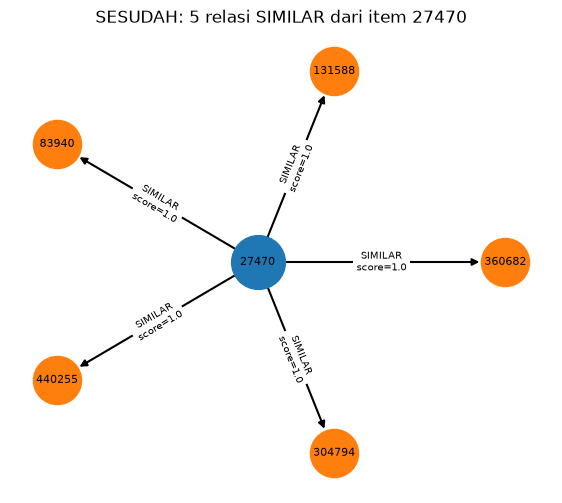

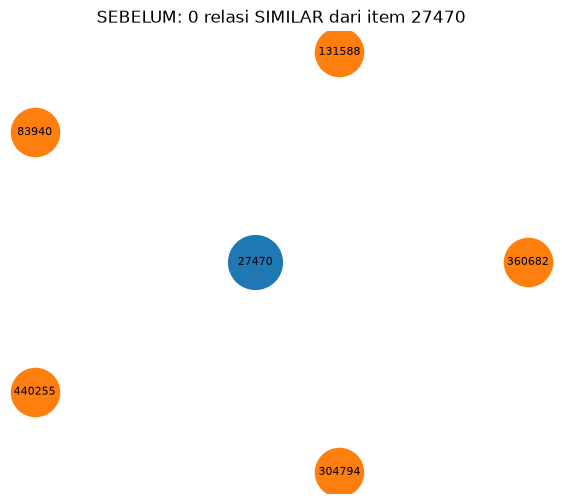

Relasi dikembalikan: 5


In [23]:
import math
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

driver = GraphDatabase.driver("bolt://127.0.0.1:7687", auth=("neo4j", PASSWORD))
ACUAN = 27470
MIRIP = [360682, 131588, 83940, 440255, 304794]

def ambil():
    with driver.session() as s:
        return s.run("""
            MATCH (a:Item {itemId: $a})-[s:SIMILAR]->(b:Item)
            WHERE b.itemId IN $m
            RETURN b.itemId AS b, s.score AS score
        """, a=ACUAN, m=MIRIP).data()

def gambar(edges, judul, nama_file):
    G = nx.DiGraph()
    pos = {ACUAN: (0, 0)}
    G.add_node(ACUAN)
    for k, m in enumerate(MIRIP):
        G.add_node(m)
        sudut = 2 * math.pi * k / len(MIRIP)
        pos[m] = (math.cos(sudut), math.sin(sudut))
    for e in edges:
        G.add_edge(ACUAN, e["b"], score=e["score"])

    plt.figure(figsize=(7, 6))
    nx.draw_networkx_nodes(G, pos, nodelist=[ACUAN], node_color="tab:blue", node_size=1500)
    nx.draw_networkx_nodes(G, pos, nodelist=MIRIP, node_color="tab:orange", node_size=1200)
    nx.draw_networkx_labels(G, pos, font_size=8)
    nx.draw_networkx_edges(G, pos, arrows=True, node_size=1400, width=1.5)
    nx.draw_networkx_edge_labels(
        G, pos, edge_labels={(u, v): f"SIMILAR\nscore={d['score']}" for u, v, d in G.edges(data=True)},
        font_size=7)
    plt.title(judul)
    plt.axis("off")
    plt.savefig(nama_file, dpi=150, bbox_inches="tight")
    plt.show()

# SESUDAH: kondisi sekarang (relasi SIMILAR masih ada)
sesudah = ambil()
gambar(sesudah, f"SESUDAH: {len(sesudah)} relasi SIMILAR dari item {ACUAN}", "sesudah.png")

try:
    # SEBELUM: hapus 5 relasi itu sementara
    with driver.session() as s:
        s.run("MATCH (:Item {itemId: $a})-[s:SIMILAR]->() DELETE s", a=ACUAN).consume()
    sebelum = ambil()
    gambar(sebelum, f"SEBELUM: {len(sebelum)} relasi SIMILAR dari item {ACUAN}", "sebelum.png")
finally:
    # kembalikan relasinya, apa pun yang terjadi
    with driver.session() as s:
        s.run("""
            UNWIND $rows AS row
            MATCH (a:Item {itemId: $a})
            MATCH (b:Item {itemId: row.b})
            MERGE (a)-[s:SIMILAR]->(b)
            SET s.score = row.score
        """, rows=sesudah, a=ACUAN).consume()
    print("Relasi dikembalikan:", len(ambil()))